# Dataset Description
## Dropout rate from school by department

**Source**: [Ministerio de Educación Nacional](https://www.datos.gov.co/Educaci-n/MEN_ESTADISTICAS_EN_EDUCACION_EN_PREESCOLAR-B-SICA/ji8i-4anb/about_data)

# Code
## Imports

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb

## Load data

In [54]:
path = "./data/MEN_ESTADISTICAS_EN_EDUCACION_EN_PREESCOLAR,_BÁSICA_Y_MEDIA_POR_DEPARTAMENTO_20261120.csv"

df = pd.read_csv(
    path, encoding="utf-8",
    usecols=[0, 2, 19, 20, 21], header=0,
    names=["year", "department", "elementary", "middle", "high"]
)

## Clean data

In [55]:
df = df[df["year"].eq(2024)].drop(columns="year")

df[["elementary", "middle", "high"]] = (
    df[["elementary", "middle", "high"]]
    .replace(r"[%]$", "", regex=True)
    .astype(float)
)

df["sum"] = df["elementary"] + df["middle"] + df["high"]
top = df.nlargest(10, "sum").sort_values("sum", ascending=False).reset_index(drop=True)
top["department"] = top["department"].replace({"Quindio": "Quindío"})

## Plot

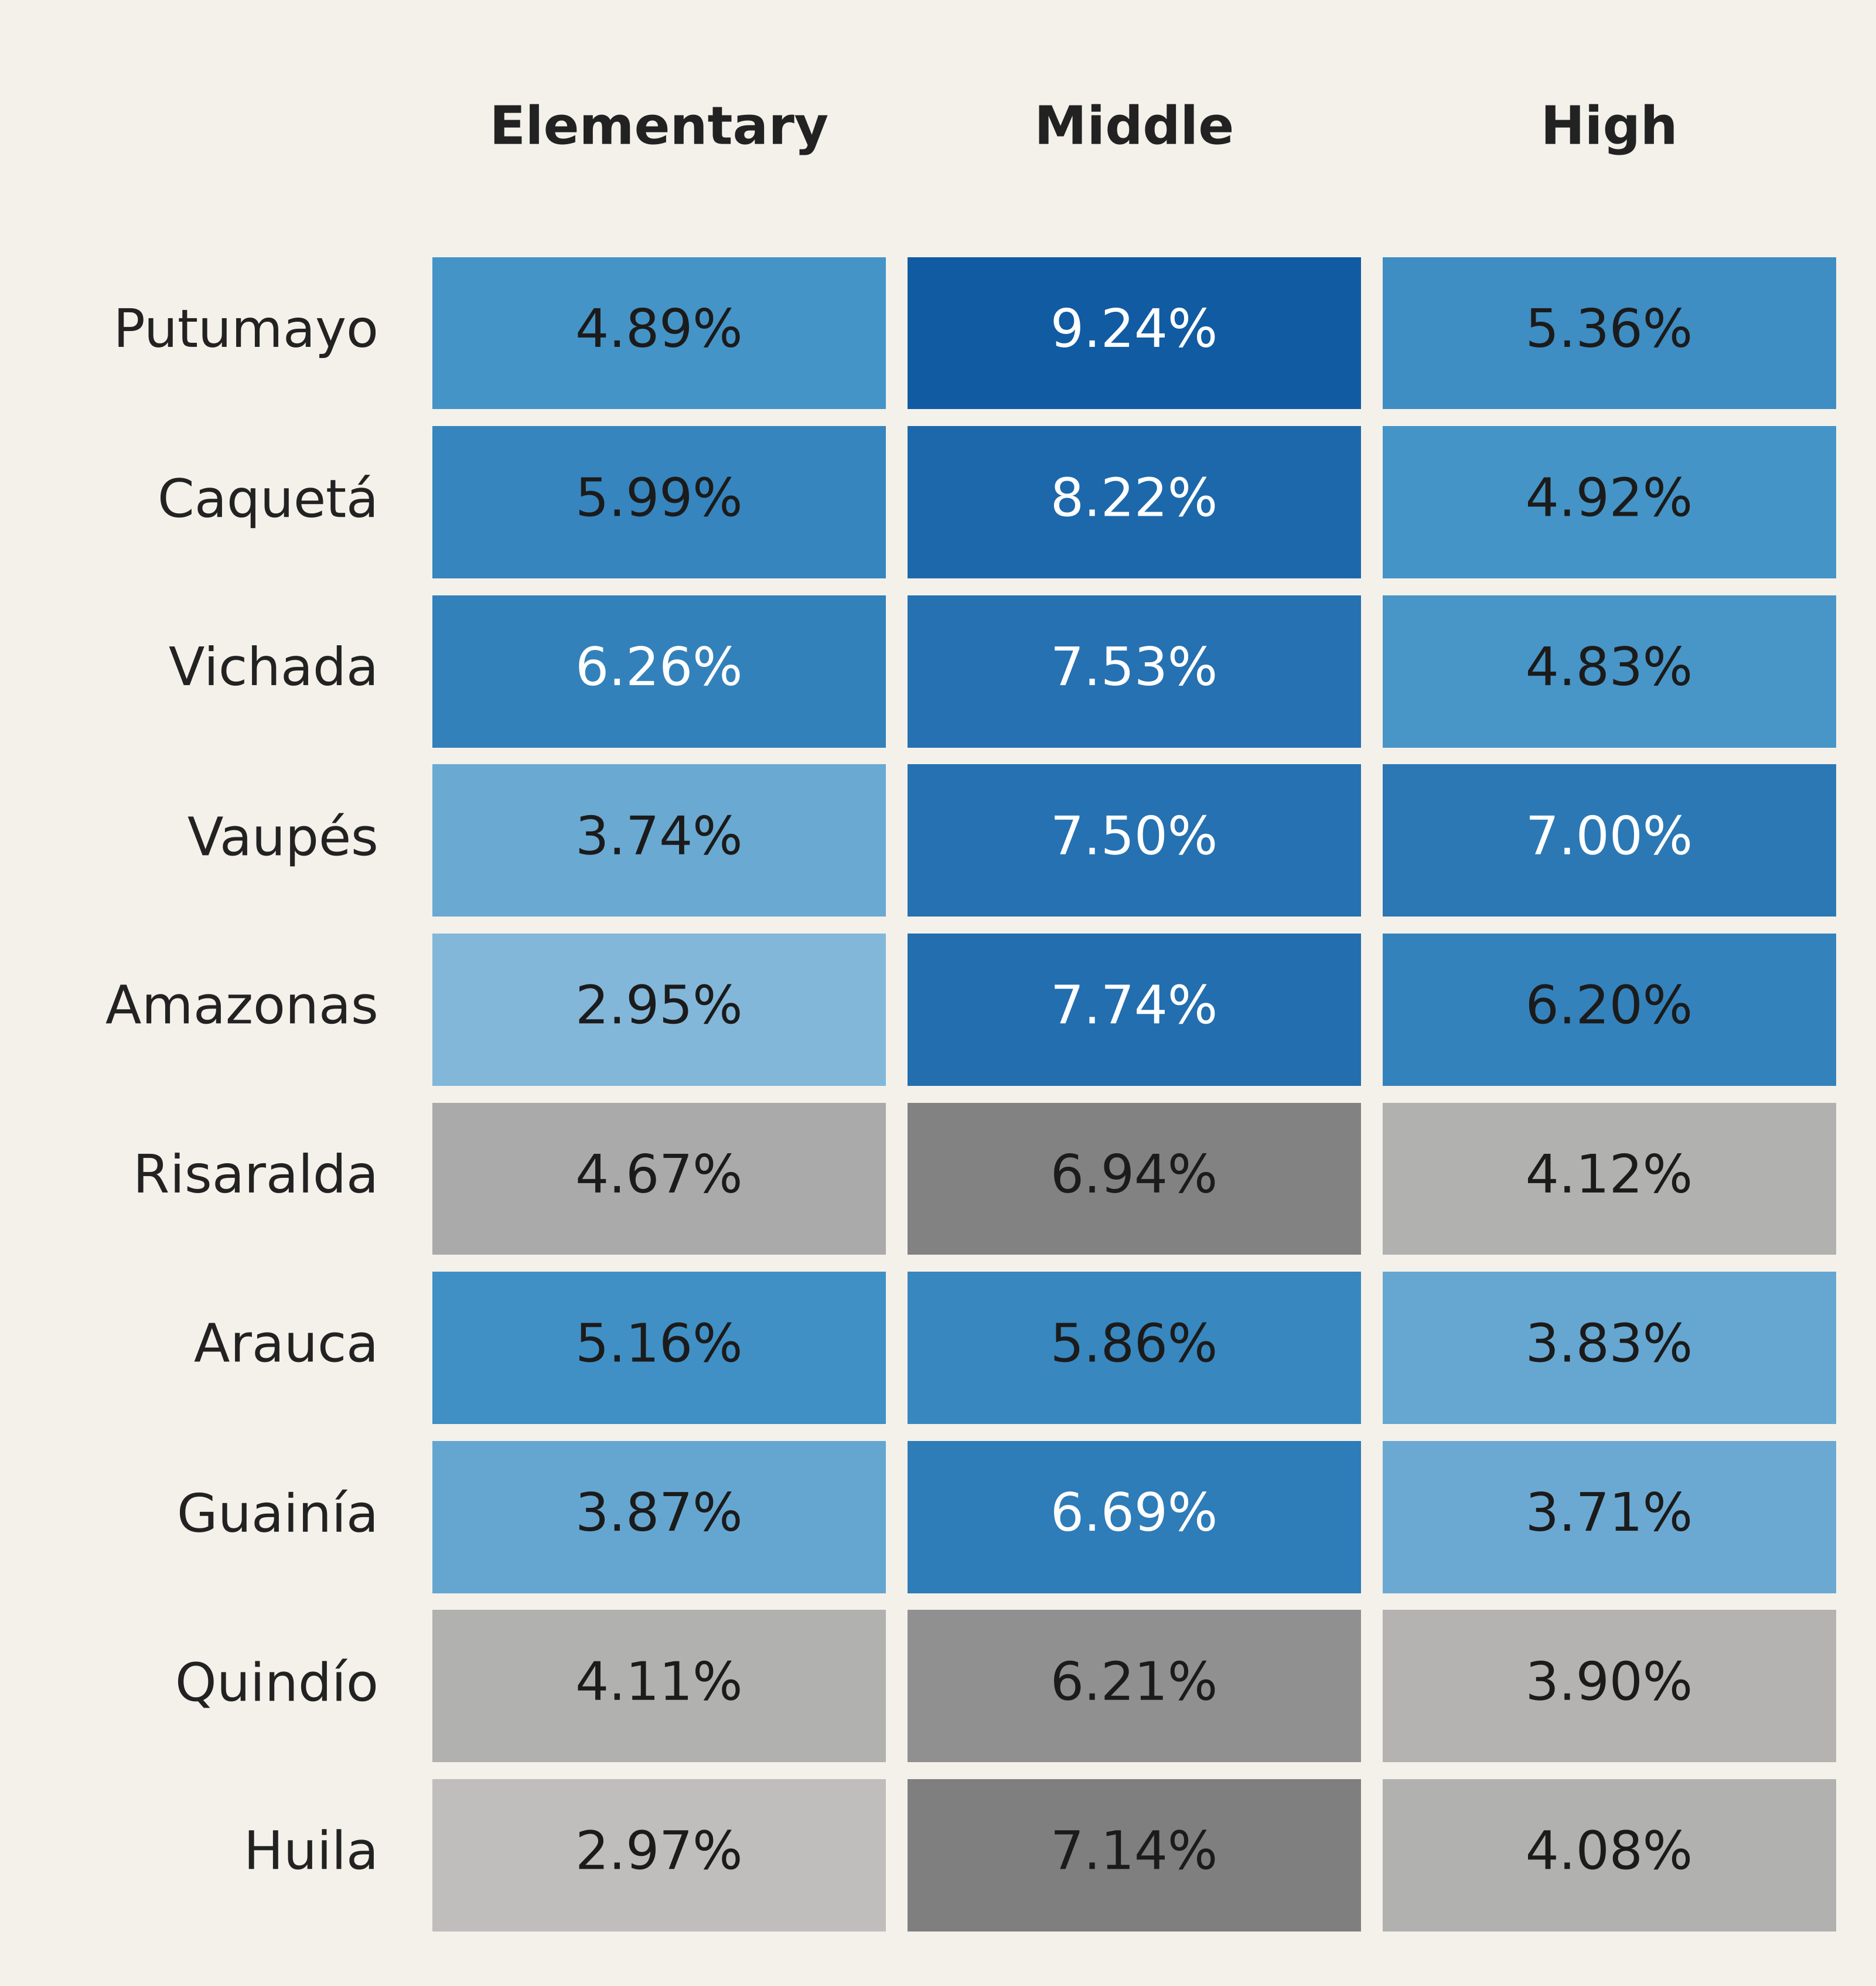

In [59]:
background = "#F4F1EA"
levels  = ["elementary", "middle", "high"]
headers = ["Elementary", "Middle", "High"]

amazon_orinoco = {"Putumayo", "Caquetá", "Vichada", "Vaupés", "Amazonas", "Arauca", "Guainía"}

cmap_blue = LinearSegmentedColormap.from_list("b", ["#DEEBF7", "#4292C6", "#08519C"])
cmap_gray = LinearSegmentedColormap.from_list("g", ["#E4E2DD", "#A6A6A6", "#4A4A4A"])
norm = Normalize(vmin=0, vmax=10)

def lum(rgb):
    c = [v / 12.92 if v <= 0.03928 else ((v + 0.055) / 1.055) ** 2.4 for v in rgb]
    return 0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2]

def text_color(rgb):
    L = lum(rgb)
    white = 1.05 / (L + 0.05)
    dark = (L + 0.05) / (lum(to_rgb("#1B1B1B")) + 0.05)
    return "white" if white >= dark else "#1B1B1B"

row_h, name_w, cell_w = 1.0, 2.0, 2.2

fig, ax = plt.subplots(figsize=(6.6, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.set_facecolor(background)

for j, h in enumerate(headers):
    ax.text(name_w + j * cell_w + cell_w / 2, -0.2, h, ha="center", va="center",
            fontsize=13, fontweight="bold", color="#222222")

pad = 0.05
name_texts = []
for i, rec in top.iterrows():
    yy = i + 1.0
    cmap = cmap_blue if rec["department"] in amazon_orinoco else cmap_gray
    name_texts.append(ax.text(name_w - 0.2, yy, rec["department"], ha="right", va="center",
                              fontsize=13, color="#222222"))
    for j, lvl in enumerate(levels):
        v = rec[lvl]
        x0 = name_w + j * cell_w
        fc = cmap(norm(v))
        ax.add_patch(Rectangle((x0 + pad, yy - row_h / 2 + pad), cell_w - 2 * pad,
                               row_h - 2 * pad, facecolor=fc, edgecolor="none"))
        ax.text(x0 + cell_w / 2, yy, f"{v:.2f}%", ha="center", va="center", fontsize=13,
                color=text_color(fc[:3]))

right = name_w + 3 * cell_w
ax.set_xlim(0, right)
ax.set_ylim(len(top) + 0.6, -0.8)
ax.axis("off")

fig.canvas.draw()
r = fig.canvas.get_renderer()
left = min(t.get_window_extent(r).transformed(ax.transData.inverted()).x0
           for t in name_texts)
ax.set_xlim(left - 0.05, right)

plt.subplots_adjust(left=0.03, right=0.97, top=0.97, bottom=0.03)
plt.show()